# 03. Phân Tách Mode Thực Nghiệm (EMD) & Vấn Đề Trộn Mode (Mode Mixing)
### Empirical Mode Decomposition (EMD) on WESAD PPG: Theory, Sifting & Pitfalls
**Tác giả:** Antigravity AI Assistant & Biomedical Signal DSP Specialist  
**Mục tiêu:**
1. Thực hành thuật toán phân tách thích nghi dữ liệu EMD (Huang et al., 1998) trên tín hiệu PPG/BVP thực tế.
2. Kiểm chứng tính chất bảo toàn năng lượng và độ chính xác tái tạo hoàn hảo (*Completeness*).
3. Phân tích hiện tượng **Mode Mixing** (trộn mode) - điểm yếu chí mạng của EMD nguyên bản.


In [1]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
from PyEMD import EMD

plt.style.use('default')
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 10,
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'axes.titleweight': 'bold',
    'figure.dpi': 130
})

DATA_PATH = r"e:\Study\S1\S1.pkl"
with open(DATA_PATH, "rb") as f:
    s1_data = pickle.load(f, encoding="latin1")

bvp_raw = s1_data['signal']['wrist']['BVP'].flatten()
fs_bvp = 64.0

# Trích xuất cửa sổ 8 giây (512 mẫu) ở trạng thái nghỉ
t_start = 120.0
win_sec = 8.0
N_win = int(win_sec * fs_bvp)

bvp_clean = bvp_raw[int(t_start*fs_bvp):int(t_start*fs_bvp) + N_win]
t_rel = np.arange(N_win) / fs_bvp

print(f"Cửa sổ PPG phân tích: N = {N_win} mẫu ({win_sec} giây, Fs = {fs_bvp} Hz)")


Cửa sổ PPG phân tích: N = 512 mẫu (8.0 giây, Fs = 64.0 Hz)


## 1. Thực Hiện Phân Rã EMD Với PyEMD
Phân tách tín hiệu thành các Hàm Mode Nội tại (IMF - Intrinsic Mode Functions) và Residue.


Số lượng IMF phân tách được: 4
Sai số tái tạo lớn nhất: 8.88e-16 (Thỏa mãn tính đầy đủ Completeness)


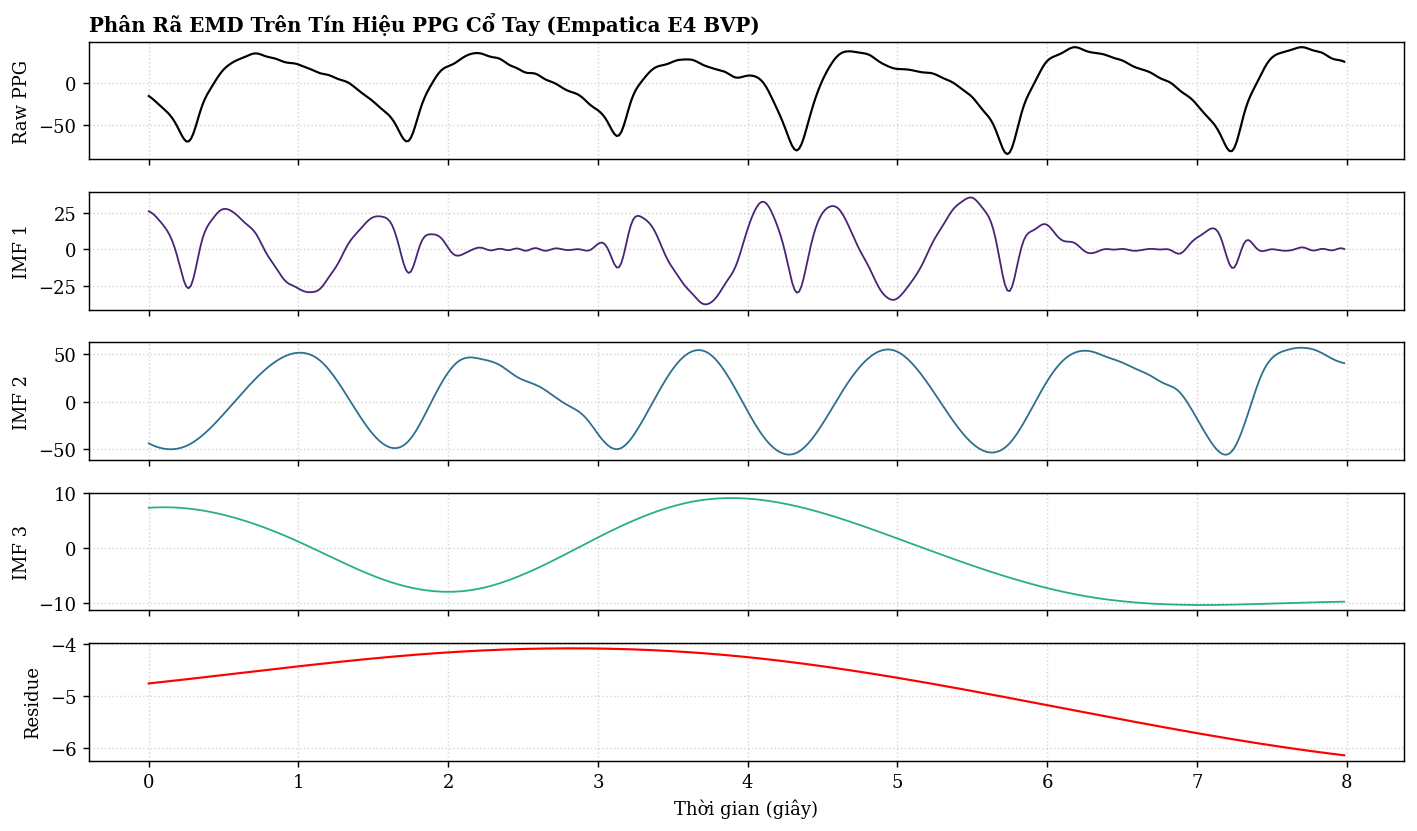

In [2]:
emd = EMD()
emd.extrema_detection = "parabol"

imfs = emd.emd(bvp_clean, t_rel)
num_imfs = imfs.shape[0]

# Tái cấu trúc
reconstructed = np.sum(imfs, axis=0)
rec_error = bvp_clean - reconstructed
max_err = np.max(np.abs(rec_error))

print(f"Số lượng IMF phân tách được: {num_imfs}")
print(f"Sai số tái tạo lớn nhất: {max_err:.2e} (Thỏa mãn tính đầy đủ Completeness)")

# Vẽ toàn bộ IMFs
fig, axes = plt.subplots(num_imfs + 1, 1, figsize=(11, 1.3 * (num_imfs + 1)), sharex=True)
axes[0].plot(t_rel, bvp_clean, 'k-', lw=1.2)
axes[0].set_ylabel('Raw PPG')
axes[0].set_title('Phân Rã EMD Trên Tín Hiệu PPG Cổ Tay (Empatica E4 BVP)', loc='left')

colors = plt.cm.viridis(np.linspace(0.1, 0.9, num_imfs))
for i in range(num_imfs):
    if i < num_imfs - 1:
        axes[i+1].plot(t_rel, imfs[i], color=colors[i], lw=1.0)
        axes[i+1].set_ylabel(f'IMF {i+1}')
    else:
        axes[i+1].plot(t_rel, imfs[i], color='red', lw=1.2)
        axes[i+1].set_ylabel('Residue')

axes[-1].set_xlabel('Thời gian (giây)')
for ax in axes:
    ax.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


## 2. Minh Hoạ Hiện Tượng Mode Mixing (Trộn Mode)
Chúng ta đưa vào một đoạn tín hiệu bị can nhiễu xung chuyển động ngắt quãng (*intermittent motion artifact*).
Khi có nhiễu xung ngắt quãng, thuật toán EMD sẽ bị trộn mode: một phần của nhịp tim bị nhảy sang IMF khác hoặc một IMF chứa cả dao động cao tần lẫn thấp tần.


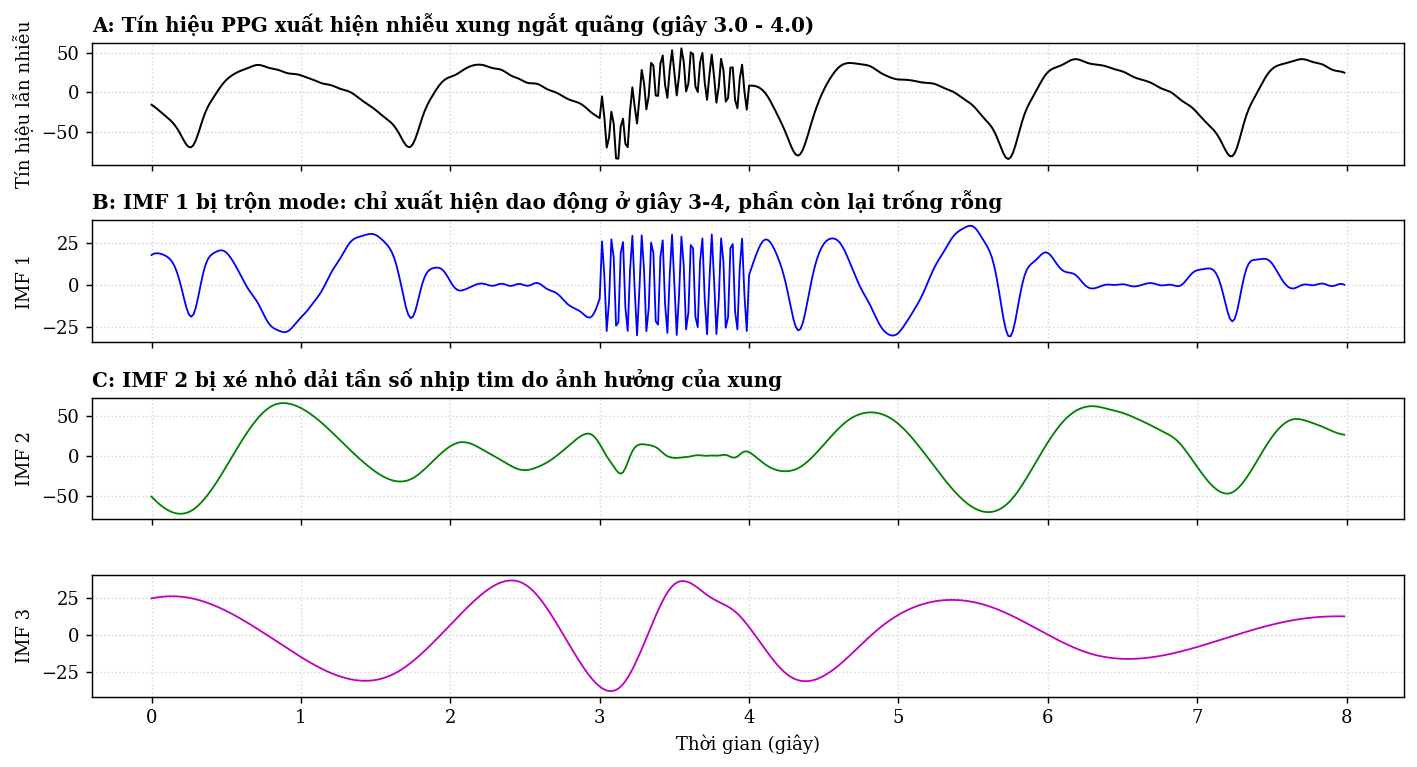

=> Mode mixing làm mất tính thuần nhất của các thành phần dao động sinh lý!


In [3]:
# Tạo tín hiệu mô phỏng có xung ngắt quãng (Intermittent high-frequency burst)
bvp_mixed = bvp_clean.copy()
# Bổ sung xung nhiễu tần số 15 Hz trong khoảng từ 3.0s đến 4.0s
burst = 30.0 * np.sin(2 * np.pi * 15.0 * t_rel) * ((t_rel >= 3.0) & (t_rel <= 4.0))
bvp_mixed += burst

imfs_mixed = emd.emd(bvp_mixed, t_rel)

fig, axes = plt.subplots(4, 1, figsize=(11, 6), sharex=True)
axes[0].plot(t_rel, bvp_mixed, 'k-', lw=1.1)
axes[0].set_ylabel('Tín hiệu lẫn nhiễu')
axes[0].set_title('A: Tín hiệu PPG xuất hiện nhiễu xung ngắt quãng (giây 3.0 - 4.0)', loc='left')

axes[1].plot(t_rel, imfs_mixed[0], 'b-', lw=1.0)
axes[1].set_ylabel('IMF 1')
axes[1].set_title('B: IMF 1 bị trộn mode: chỉ xuất hiện dao động ở giây 3-4, phần còn lại trống rỗng', loc='left')

axes[2].plot(t_rel, imfs_mixed[1], 'g-', lw=1.0)
axes[2].set_ylabel('IMF 2')
axes[2].set_title('C: IMF 2 bị xé nhỏ dải tần số nhịp tim do ảnh hưởng của xung', loc='left')

axes[3].plot(t_rel, imfs_mixed[2], 'm-', lw=1.0)
axes[3].set_ylabel('IMF 3')
axes[3].set_xlabel('Thời gian (giây)')

for ax in axes:
    ax.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()
print("=> Mode mixing làm mất tính thuần nhất của các thành phần dao động sinh lý!")


## Kết Luận Notebook 3:
- EMD thích nghi hoàn toàn theo dữ liệu mà không cần hàm cơ sở giả định.
- Tuy nhiên, khi gặp tín hiệu y sinh thực tế có nhiễu xung hoặc vận động ngắt quãng, EMD gặp hiện tượng **Mode Mixing** nghiêm trọng, đòi hỏi giải pháp hỗ trợ nhiễu (*Noise-Assisted*) như EEMD hoặc CEEMDAN.
